In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, mean_squared_error

from pathlib import Path

In [2]:
# Cấu hình đường dẫn theo cây thư mục project/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "weather_clean.csv"
PARAMS_PATH = PROJECT_ROOT / "results" / "lightgbm" / "lightgbm_best_params.json"
OUTPUT_DIR = PROJECT_ROOT / "results" / "forecast_H2_2026"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
# Đọc dữ liệu
df = pd.read_csv(DATA_PATH)

# Kiểm tra các cột
print("Các cột trong dữ liệu:")
print(df.columns.tolist())

# Chuyển đổi kiểu dữ liệu
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["tavg"] = pd.to_numeric(df["tavg"], errors="coerce")

# Loại bỏ dòng thiếu ngày hoặc nhiệt độ trung bình
df = df.dropna(subset=["date", "tavg"]).copy()

# Sắp xếp dữ liệu theo ngày
df = df.sort_values("date").reset_index(drop=True)

print("\nSố dòng hợp lệ:", len(df))
print("Ngày đầu tiên:", df["date"].min().date())
print("Ngày cuối cùng:", df["date"].max().date())
print("Số ngày bị trùng:", df["date"].duplicated().sum())

# Hiển thị 5 dòng đầu
display(df.head())

Các cột trong dữ liệu:
['date', 'tavg', 'tmin', 'tmax', 'prcp', 'snow', 'wspd', 'wpgt', 'pres', 'tsun', 'split', 'co_ngoai_lai_tavg']

Số dòng hợp lệ: 2373
Ngày đầu tiên: 2020-01-01
Ngày cuối cùng: 2026-06-30
Số ngày bị trùng: 0


,date,tavg,tmin,tmax,prcp,snow,wspd,wpgt,pres,tsun,split,co_ngoai_lai_tavg
0,2020-01-01,0.4,-3.6,4.5,0.1,0,10.1,22.3,1035.5,438,train,False
1,2020-01-02,-0.5,-2.4,1.4,0.0,0,6.1,25.9,1031.2,0,train,False
2,2020-01-03,5.8,1.3,9.3,0.5,0,15.5,46.8,1024.4,0,train,False
3,2020-01-04,5.4,2.4,6.8,0.2,0,15.8,47.5,1031.5,0,train,False
4,2020-01-05,4.8,2.7,6.3,1.1,0,6.8,23.4,1036.6,0,train,False


In [4]:
def create_lightgbm_features(
    df_in: pd.DataFrame,
    fourier_k: int = 3,
) -> tuple[pd.DataFrame, list[str]]:
  data = df_in.copy()
  doy = data["date"].dt.dayofyear

  data["time_month"] = data["date"].dt.month
  data["time_dayofyear"] = doy
  data["time_weekofyear"] = data["date"].dt.isocalendar().week.astype(int)

  for k in range(1, fourier_k + 1):
    data[f"time_sin_{k}"] = np.sin(2.0 * np.pi * k * doy / 365.25)
    data[f"time_cos_{k}"] = np.cos(2.0 * np.pi * k * doy / 365.25)

  s365 = data["tavg"].shift(365)
  s730 = data["tavg"].shift(730)

  data["ar_tavg_lag_365"] = s365
  data["ar_tavg_lag_730"] = s730
  data["ar_tavg_same_day_2yr_mean"] = 0.5 * (s365 + s730)

  for win in [7, 14, 30]:
    data[f"ar_tavg_lag365_roll_mean_{win}"] = s365.rolling(
        window=win, min_periods=1
    ).mean()

  data["ar_tavg_lag365_roll_std_14"] = s365.rolling(
      window=14, min_periods=2
  ).std()

  feature_cols = [
      c for c in data.columns if c.startswith(("time_", "ar_"))
  ]
  return data, feature_cols

In [5]:
# Lọc dữ liệu lịch sử đến 30/06/2026 và ghép thêm 184 ngày tương lai H2/2026
train_end_date = pd.Timestamp("2026-06-30")
df_hist = df[df["date"] <= train_end_date][["date", "tavg"]].copy()

future_H2_2026 = pd.DataFrame({
    "date": pd.date_range(start="2026-07-01", end="2026-12-31", freq="D"),
    "tavg": np.nan,
})

# Gộp chung để shift(365) và shift(730) liền mạch cho H2/2026
df_full = pd.concat([df_hist, future_H2_2026], ignore_index=True)
df_feat, feature_cols = create_lightgbm_features(df_full)

# Giữ đúng quy tắc của N3: chỉ loại các dòng thiếu lag_365 (365 dòng đầu).
# Các dòng thiếu lag_730 và same_day_2yr_mean được giữ lại (LightGBM xử lý NaN).
train_df = (
    df_feat[df_feat["date"] <= train_end_date]
    .dropna(subset=["ar_tavg_lag_365", "tavg"])
    .reset_index(drop=True)
)
X_train = train_df[feature_cols]
y_train = train_df["tavg"]

future_df = df_feat[df_feat["date"] >= "2026-07-01"].reset_index(drop=True)
X_future = future_df[feature_cols]

print("Số lượng biến đặc trưng:", len(feature_cols))
print("Số quan sát huấn luyện:", len(X_train))
print("Số ngày cần dự báo (H2/2026):", len(X_future))

assert len(X_train) == 2008, f"Số dòng huấn luyện phải là 2008, hiện là {len(X_train)}"
assert len(X_future) == 184, "Số ngày dự báo phải là 184"
assert X_future[["ar_tavg_lag_365", "ar_tavg_lag_730"]].notna().all().all(), "Đặc trưng lag của H2 bị NaN"

Số lượng biến đặc trưng: 16
Số quan sát huấn luyện: 2008
Số ngày cần dự báo (H2/2026): 184


In [6]:
with open(PARAMS_PATH, "r", encoding="utf-8") as f:
  cfg = json.load(f)

# Lấy khối best_params
if "best_params" in cfg and isinstance(cfg["best_params"], dict):
  best_params = cfg["best_params"]
else:
  best_params = cfg

print("Bộ tham số tối ưu được nạp:", best_params)

# Khởi tạo mô hình với n_estimators và các tham số cố định
final_model = lgb.LGBMRegressor(
    **best_params,
    n_estimators=cfg.get("n_estimators", 213),
    subsample_freq=1,
    random_state=cfg.get("random_state", 42),
    objective="regression"
)

final_model.fit(X_train, y_train)
print("Đã refit mô hình LightGBM thành công!")

Bộ tham số tối ưu được nạp: {'max_depth': 2, 'num_leaves': 4, 'learning_rate': 0.02, 'min_child_samples': 50, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_alpha': 1.0, 'reg_lambda': 1.0}
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000822 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3607
[LightGBM] [Info] Number of data points in the train set: 2008, number of used features: 16
[LightGBM] [Info] Start training from score 11.832221
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Đã refit mô hình L

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

In [7]:
forecast_preds = final_model.predict(X_future)

forecast_result = pd.DataFrame({
    "date": future_df["date"],
    "forecast_tavg": forecast_preds,
})

display(forecast_result.head())

,date,forecast_tavg
0,2026-07-01,21.091180
1,2026-07-02,20.917215
2,2026-07-03,20.547663
3,2026-07-04,20.601525
4,2026-07-05,20.721628


Đã lưu file thành công: c:\Users\ASUS\Frankfurt_Temperature_Forecasting\results\forecast_H2_2026\Du_bao_H2_2026_LightGBM.csv


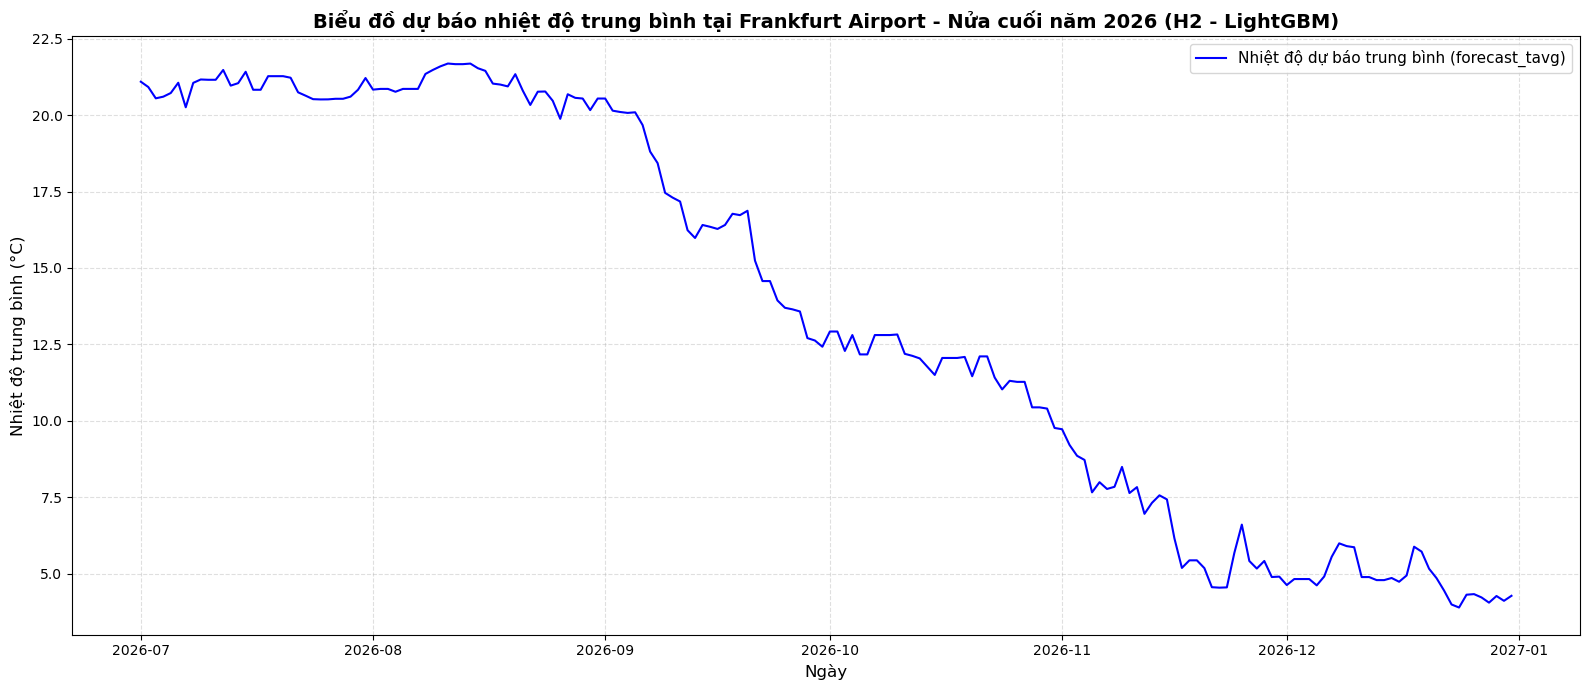

Đã vẽ và lưu biểu đồ thành công: c:\Users\ASUS\Frankfurt_Temperature_Forecasting\results\forecast_H2_2026\Bieu_do_du_bao_H2_2026.png


In [8]:
# Kiểm tra dự báo không NaN và đúng 184 dòng
assert len(forecast_result) == 184, "Số dòng dự báo không bằng 184"
assert not forecast_result["forecast_tavg"].isna().any(), "Kết quả dự báo chứa NaN"

# Lưu kết quả ra file CSV
csv_output_path = OUTPUT_DIR / "Du_bao_H2_2026_LightGBM.csv"
forecast_result.to_csv(csv_output_path, index=False, encoding="utf-8-sig")
print("Đã lưu file thành công:", csv_output_path)

# Vẽ biểu đồ dự báo H2/2026
plt.figure(figsize=(16, 7))
plt.plot(
    forecast_result["date"],
    forecast_result["forecast_tavg"],
    color="blue",
    linewidth=1.5,
    label="Nhiệt độ dự báo trung bình (forecast_tavg)",
)

plt.title(
    "Biểu đồ dự báo nhiệt độ trung bình tại Frankfurt Airport - Nửa cuối năm"
    " 2026 (H2 - LightGBM)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Ngày", fontsize=12)
plt.ylabel("Nhiệt độ trung bình (°C)", fontsize=12)
plt.legend(loc="best", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()

plot_output_path = OUTPUT_DIR / "Bieu_do_du_bao_H2_2026.png"
plt.savefig(plot_output_path, dpi=300, bbox_inches="tight")
plt.show()
print("Đã vẽ và lưu biểu đồ thành công:", plot_output_path)